<a href="https://colab.research.google.com/github/tmysvdsn1998-art/Kaggle-Tryouts-/blob/main/1_Titanic_Kaggle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("train.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# peek into the data
df.head(20)
#remove
useful_data = df.drop(columns=["PassengerId", "Cabin"])

In [ ]:
# Overall survival percentage
print("Survived =",useful_data["Survived"].mean() * 100, "%")
# Survival percentage by sex
print(useful_data.groupby("Sex")["Survived"].mean() * 100)
# Survival percentage by passenger class
print(useful_data.groupby("Pclass")["Survived"].mean() * 100)

Survived = 38.38383838383838 %
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


Text(0.5, 1.0, 'Titanic Passengers: Age vs Fare \n (Color = Survival, Shape = Gender)')

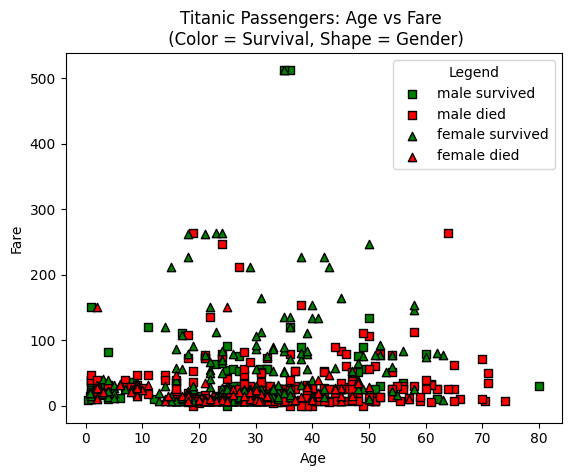

In [ ]:
#Uni Lessons tryout - setting the points for the graphs in various shapes and colours
for sex, shape in (('male', 's'),('female','^')):
  for survived, color, status in ((1, 'green', 'survived'),((0, 'red', 'died'))):

    sex_data_group = df[df['Sex']== sex]
    sex_survived_data_group = sex_data_group[sex_data_group['Survived'] == survived]
    label_combined = sex +" "+ status
    plt.scatter(sex_survived_data_group['Age'],
                sex_survived_data_group['Fare'],
                c=color,
                marker=shape,
                label=label_combined,
                edgecolor = 'black')

#visuals of graph (overall)
plt.xlabel('Age')
plt.ylabel('Fare')
plt.legend(title = "Legend")
plt.title('Titanic Passengers: Age vs Fare \n (Color = Survival, Shape = Gender)')



In [ ]:
from sklearn.model_selection import train_test_split

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = useful_data[features].copy()  # information used to predict
y = useful_data["Survived"]       # answer we want to predict

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.02,
    random_state=42,
    stratify=y
)
print(X_valid["Sex"].unique())
print(X_train["Embarked"].value_counts(dropna=False))

['male' 'female']
Embarked
S      629
C      167
Q       75
NaN      2
Name: count, dtype: int64


In [ ]:
# Fill missing values using training data
median_age = X_train["Age"].median()
most_common_port = X_train["Embarked"].mode().iloc[0]

X_train["Age"] = X_train["Age"].fillna(median_age)
X_valid["Age"] = X_valid["Age"].fillna(median_age)

X_train["Embarked"] = X_train["Embarked"].fillna(most_common_port)
X_valid["Embarked"] = X_valid["Embarked"].fillna(most_common_port)

# Encode text values ONCE
for data in [X_train, X_valid]:
    data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
    data["Embarked"] = data["Embarked"].map({"S": 0, "C": 1, "Q": 2})



In [ ]:
print(X_train["Age"].isna().sum())
print(X_valid["Age"].isna().sum())

0
0


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

model = DecisionTreeClassifier(max_depth=3, random_state=42)

# Learn from the training features and their correct answers
model.fit(X_train, y_train)

# Predict survival for the validation passengers
predictions = model.predict(X_valid)

# Compare predictions with the actual answers
print(accuracy_score(y_valid, predictions))

0.7777777777777778


In [ ]:
print(X_train.isna().sum())
print(X_valid.isna().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
#Shallow NN
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(5,),
        max_iter=1000,
        random_state=42
    )
)

model.fit(X_train, y_train)

predictions = model.predict(X_valid)
print(accuracy_score(y_valid, predictions))

0.8333333333333334


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_valid)

print(accuracy_score(y_valid, predictions))

0.8333333333333334


In [ ]:
model.fit(X_train, y_train)

# Predict without showing the model the correct answers
predictions = model.predict(X_valid)

# Compare predictions with the answers
score = accuracy_score(y_valid, predictions)
print(f"Validation accuracy: {score:.2%}")

Validation accuracy: 83.33%


In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_valid, predictions))

#[[correctly predicted deaths, incorrectly predicted survival],
 #[incorrectly predicted deaths, correctly predicted survival]]

[[9 2]
 [1 6]]


In [ ]:
test_df = pd.read_csv("test.csv")

# Select the same features and column order as training
X_test = test_df[X_train.columns].copy()

# Use the values you calculated from training data
X_test["Age"] = X_test["Age"].fillna(median_age)
X_test["Embarked"] = X_test["Embarked"].fillna(most_common_port)
X_test["Fare"] = X_test["Fare"].fillna(X_train["Fare"].median())

# Apply your existing encoding once
X_test["Sex"] = X_test["Sex"].map({"male": 0, "female": 1})
X_test["Embarked"] = X_test["Embarked"].map({"S": 0, "C": 1, "Q": 2})

In [ ]:
print(X_test.isna().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
test_predictions = model.predict(X_test)

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions
})

submission.to_csv("submission.csv", index=False)